### Практичне завдання №3 Дослідження ефективності TF-IDF зважених ембеддингів для детекції текстів, згенерованих великими мовними моделями

#### Мета роботи

Засвоїти принципи побудови векторних представлень текстів на основі субсловних ембеддингів FastText, дослідити вплив TF-IDF зважування на якість агрегації документних векторів, порівняти ефективність лінійних та нелінійних методів класифікації (SVM, Logistic Regression, KNN) у задачі бінарної детекції штучно згенерованих текстів, а також проаналізувати геометричні властивості отриманих векторних просторів.


Імпорт бібліотек та налаштування середовища

In [2]:
# Робота з даними
import numpy as np
import pandas as pd

# Візуалізація
import matplotlib.pyplot as plt
import seaborn as sns

# Обробка тексту
import spacy

# Навчання FastText
from gensim.models import FastText

# Векторизація та класифікація
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier

# Метрики оцінювання
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    balanced_accuracy_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

# Зменшення розмірності
from sklearn.manifold import TSNE

# Додаткові інструменти
import warnings

warnings.filterwarnings("ignore")

# Налаштування відображення графіків
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

print("Бібліотеки успішно імпортовано!")

Бібліотеки успішно імпортовано!


### Етап 2. Завантаження та первинний аналіз даних
1. Завантаження та первинний аналіз даних

На цьому етапі виконується завантаження набору даних AI vs Human Text Classification Dataset 2026 та аналіз його структури.

Датасет містить тексти двох класів:

human — тексти, написані людьми;

ai — тексти, згенеровані великими мовними моделями.

Кожен запис містить ідентифікатор тексту, клас, інформацію про джерело генерації, тематичну категорію, текстовий вміст та додаткові характеристики.

Основною ознакою для подальшого дослідження буде text_content, а цільовою змінною — label.


1. Завантаження та первинний аналіз даних

На цьому етапі виконується завантаження набору даних AI vs Human Text Classification Dataset 2026 та аналіз його структури.

Датасет містить тексти двох класів:
- human - тексти, написані людьми;
- ai - тексти, згенеровані великими мовними моделями.

Кожен запис містить ідентифікатор тексту, клас, інформацію про джерело генерації, тематичну категорію, текстовий вміст та додаткові характеристики.

Основною ознакою для подальшого дослідження буде text_content, а цільовою змінною label.

In [4]:
# Шлях до датасету
DATASET_PATH = "ai_vs_human_text_2026.csv"

# Завантаження даних
df = pd.read_csv(DATASET_PATH)

# Відображення перших п'яти записів
display(df.head())

,text_id,label,source_model,domain,text_content,topic_hint,word_count,avg_sentence_length,generation_method
0,TXT_0001,human,human,social,can we talk about gene editing ethics for a se...,gene editing ethics,27,13.5,template+human_variation
1,TXT_0002,human,human,social,update on election integrity concerns: it's co...,election integrity concerns,20,10.0,template+human_variation
2,TXT_0003,ai,gemini-2.0,news,Analysts are closely watching developments rel...,climate change adaptation strategies,39,13.0,style_simulation
3,TXT_0004,human,human,academic,This paper examines genomic research breakthro...,genomic research breakthroughs,49,16.3,template+human_variation
4,TXT_0005,ai,gpt-4o,academic,Existing literature on student debt crisis has...,student debt crisis,42,10.8,style_simulation


1.1. Аналіз структури датасету

Для отримання загального уявлення про набір даних визначимо кількість записів, кількість стовпців, типи даних та наявність пропущених значень.

Це дозволить перевірити коректність завантаження даних і визначити, чи потрібна додаткова обробка.

In [5]:
# Розмір датасету
print("Розмір датасету:", df.shape)

# Назви стовпців
print("\nНазви стовпців:")
print(df.columns.tolist())

# Типи даних
print("\nТипи даних:")
print(df.dtypes)

# Загальна інформація
print("\nІнформація про датасет:")
df.info()

# Кількість пропущених значень
print("\nПропущені значення:")
display(df.isnull().sum().to_frame(name="Кількість пропусків"))

Розмір датасету: (2000, 9)

Назви стовпців:
['text_id', 'label', 'source_model', 'domain', 'text_content', 'topic_hint', 'word_count', 'avg_sentence_length', 'generation_method']

Типи даних:
text_id                    str
label                      str
source_model               str
domain                     str
text_content               str
topic_hint                 str
word_count               int64
avg_sentence_length    float64
generation_method          str
dtype: object

Інформація про датасет:
<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 9 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   text_id              2000 non-null   str    
 1   label                2000 non-null   str    
 2   source_model         2000 non-null   str    
 3   domain               2000 non-null   str    
 4   text_content         2000 non-null   str    
 5   topic_hint           2000 non-null   str

,Кількість пропусків
text_id,0
label,0
source_model,0
domain,0
text_content,0
topic_hint,0
word_count,0
avg_sentence_length,0
generation_method,0


### 1.2. Аналіз розподілу класів

Для оцінювання збалансованості набору даних визначимо кількість текстів кожного класу та їхню частку від загальної кількості записів.

Збалансованість класів важлива для коректного навчання класифікаторів та інтерпретації отриманих метрик якості.

,Кількість текстів,Частка (%)
label,,
human,1334,66.7
ai,666,33.3


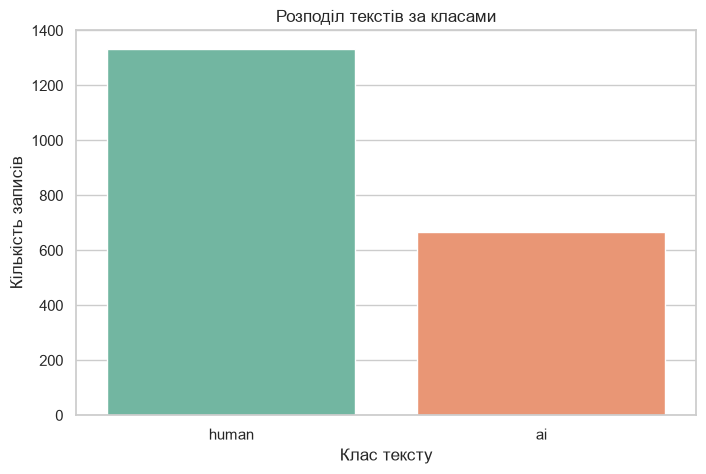

In [6]:
# Кількість текстів кожного класу
class_counts = df["label"].value_counts()

# Відсоткове співвідношення класів
class_percentages = df["label"].value_counts(normalize=True) * 100

# Формування таблиці
class_distribution = pd.DataFrame({
    "Кількість текстів": class_counts,
    "Частка (%)": class_percentages.round(2)
})

display(class_distribution)

# Візуалізація розподілу класів
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="label",
    hue="label",
    order=["human", "ai"],
    palette="Set2",
    legend=False
)

plt.title("Розподіл текстів за класами")
plt.xlabel("Клас тексту")
plt.ylabel("Кількість записів")
plt.show()

**Висновок:** 

За результатами аналізу розподілу класів можна визначити, чи є датасет збалансованим. Якщо кількість текстів класів AI та Human приблизно однакова, набір даних є збалансованим. Якщо спостерігається суттєва різниця, це необхідно враховувати під час оцінювання моделей.

### 1.3. Виявлення можливих артефактів

На цьому етапі перевіряються можливі проблеми в наборі даних:

- дублікати текстів;
- дублікати ідентифікаторів;
- порожні або текстові записи, що складаються лише з пробілів;
- надмірно короткі тексти.

Наявність таких артефактів може негативно впливати на навчання моделей та достовірність оцінювання їхньої якості.

Для виявлення коротких текстів використовується поріг у 5 слів.

In [7]:
# Кількість дублікатів текстів
duplicate_texts = df["text_content"].duplicated().sum()

# Кількість дублікатів ідентифікаторів
duplicate_ids = df["text_id"].duplicated().sum()

# Перевірка порожніх текстів
empty_texts = df["text_content"].str.strip().eq("").sum()

# Обчислення фактичної кількості слів у кожному тексті
df["actual_word_count"] = df["text_content"].str.split().str.len()

# Виявлення надмірно коротких текстів (менше 5 слів)
short_texts = (df["actual_word_count"] < 5).sum()

# Формування таблиці результатів
artifacts = pd.DataFrame({
    "Тип перевірки": [
        "Дублікати текстів",
        "Дублікати ID",
        "Порожні тексти",
        "Тексти коротші за 5 слів"
    ],
    "Кількість": [
        duplicate_texts,
        duplicate_ids,
        empty_texts,
        short_texts
    ]
})

display(artifacts)

# Виведення прикладів коротких текстів
print("Приклади коротких текстів:")
display(
    df.loc[
        df["actual_word_count"] < 5,
        ["label", "text_content", "actual_word_count"]
    ].head(10)
)

,Тип перевірки,Кількість
0,Дублікати текстів,1034
1,Дублікати ID,0
2,Порожні тексти,0
3,Тексти коротші за 5 слів,0


Приклади коротких текстів:


,label,text_content,actual_word_count


### 1.4. Аналіз довжини текстів

Для дослідження характеристик текстових документів проаналізуємо кількість слів у текстах кожного класу.

Будуть розраховані основні статистичні характеристики:
- середня кількість слів;
- стандартне відхилення;
- мінімальна та максимальна довжина;
- медіана;
- перший і третій квартилі.

Це дозволить визначити, чи відрізняються тексти, написані людьми, від текстів, згенерованих штучним інтелектом, за обсягом.

In [8]:
# Статистичні характеристики довжини текстів
length_statistics = df.groupby("label")["actual_word_count"].describe()

display(length_statistics.round(2))

,count,mean,std,min,25%,50%,75%,max
label,,,,,,,,
ai,666.0,38.00,7.01,23.0,35.0,39.0,44.0,50.0
human,1334.0,36.51,9.66,19.0,27.0,36.0,46.0,52.0


### 1.5. Візуалізація розподілу довжини текстів

Для наочного порівняння довжини документів побудуємо окремі гістограми для класів Human та AI.

Гістограми дозволять оцінити характер розподілу кількості слів, розкид значень та можливі відмінності між двома категоріями текстів.

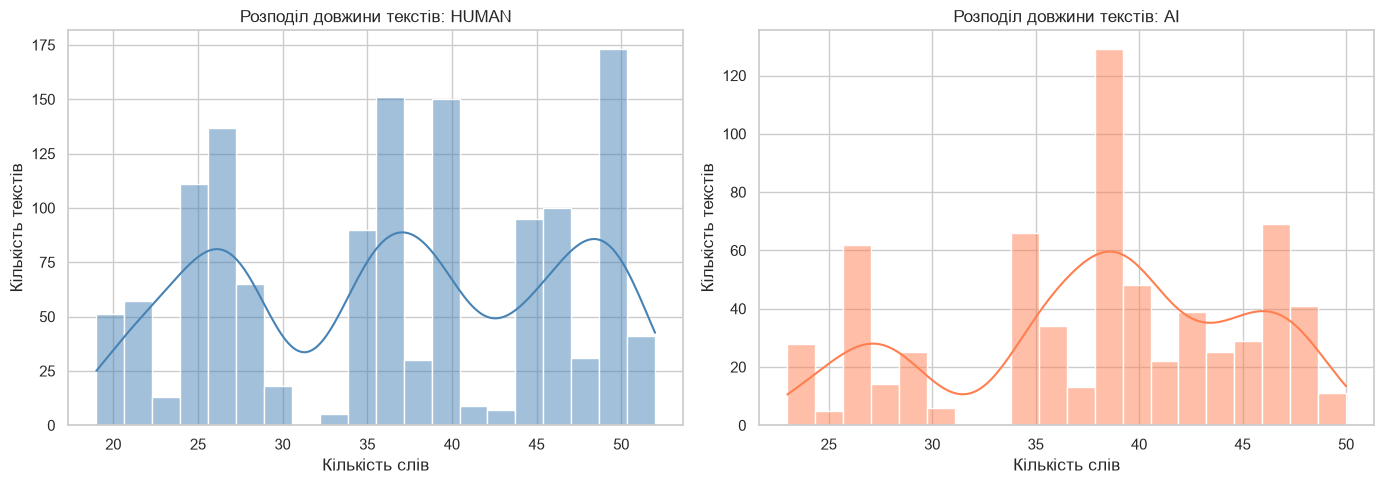

In [9]:
# Побудова гістограм для кожного класу
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

classes = ["human", "ai"]
colors = ["steelblue", "coral"]

for ax, class_name, color in zip(axes, classes, colors):

    class_data = df.loc[
        df["label"] == class_name,
        "actual_word_count"
    ]

    sns.histplot(
        class_data,
        bins=20,
        kde=True,
        color=color,
        ax=ax
    )

    ax.set_title(f"Розподіл довжини текстів: {class_name.upper()}")
    ax.set_xlabel("Кількість слів")
    ax.set_ylabel("Кількість текстів")

plt.tight_layout()
plt.show()

На графіках видно, що тексти обох класів мають майже однакову довжину - приблизно від 19 до 52 слів. У людських текстів (Human) довжина розподілена рівномірніше, з кількома піками, а в AI-текстів є чіткий пік близько 38 слів, тобто вони частіше бувають середнього розміру. Оскільки класи сильно перекриваються за довжиною, ця ознака не допоможе відрізнити AI від людини. Тому для класифікації потрібно дивитися не на кількість слів, а на самі слова - тобто використовувати ембеддинги та TF-IDF.



### Висновок до етапу 1

У результаті первинного аналізу було досліджено структуру та якість набору даних AI vs Human Text Classification Dataset 2026.

Встановлено, що датасет містить 2000 текстових записів та 9 стовпців. Пропущені значення відсутні.

Розподіл класів є незбалансованим: тексти Human становлять 66,7%, а AI - 33,3% від загальної кількості записів. Це необхідно враховувати під час подальшого оцінювання класифікаторів.

Додатково було перевірено наявність дублікатів, порожніх і коротких текстів, а також досліджено розподіл довжини документів.

[Доповнити висновок після отримання результатів перевірок та гістограм.]

### 1.6. Перевірка дублікатів текстів і узгодженості міток

Оскільки в наборі даних було виявлено значну кількість повторюваних текстів, необхідно перевірити узгодженість їхніх міток.

Особливу увагу приділимо текстам, які зустрічаються в обох класах (`human` та `ai`). Такі випадки можуть створювати суперечності під час навчання класифікаторів.

Також ця перевірка допоможе уникнути потрапляння однакових текстів одночасно до навчальної та тестової вибірок.

In [13]:
duplicate_analysis = (
    df.groupby("text_content")
    .agg(
        occurrences=("label", "size"),
        unique_labels=("label", "nunique"),
        labels=("label", lambda x: ", ".join(sorted(x.unique())))
    )
    .reset_index()
)

conflicting_duplicates = duplicate_analysis[
    duplicate_analysis["unique_labels"] > 1
]

print("Кількість унікальних текстів:", df["text_content"].nunique())
print("Текстів із суперечливими мітками:", len(conflicting_duplicates))
print(
    "Кількість записів із суперечливими мітками:",
    conflicting_duplicates["occurrences"].sum()
)

display(conflicting_duplicates.head(10))

Кількість унікальних текстів: 966
Текстів із суперечливими мітками: 0
Кількість записів із суперечливими мітками: 0


,text_content,occurrences,unique_labels,labels
